# Composite and Distance-Modulated Initialization

The basic initializers of the previous tutorials become more expressive when combined. This tutorial covers every way `braintools.init` builds one initializer out of others:

| Tool | Result |
|---|---|
| `a + b`, `a - b`, `a * b`, `a / b` (initializers or constants) | elementwise arithmetic of independent draws |
| `a.clip(min, max)`, `a.add(c)`, `a.multiply(c)`, `a.apply(f)`, `a | f` | transformed draws |
| `Compose(a, f, g, ...)` | `g(f(a(shape)))` |
| `Scaled(a, k)`, `Clipped(a, min, max)` | class forms of `a * k` and `a.clip(min, max)` |
| `Mixture([a, b, ...], weights)` | each element drawn from a randomly chosen component |
| `Conditional(condition_fn, a, b)` | each element drawn from `a` or `b` depending on its index |
| `DistanceModulated(a, profile)` | `a(shape) * profile(distances)` |

At the end, `param` shows how any of these (or a plain number or array) becomes a parameter of a model.

## 1. Setup

In [1]:
import brainunit as u
import matplotlib.pyplot as plt
import numpy as np

from braintools import init

rng = np.random.default_rng(0)

## 2. Arithmetic and Transformations

Arithmetic on initializers builds an expression tree; nothing is sampled until the result is called. Each initializer in the tree makes its **own independent draw**, so `Normal(...) + Normal(...)` is the sum of two independent samples (variances add), not twice one sample.

In [2]:
base = init.Normal(1.0 * u.nS, 0.1 * u.nS)

shifted = base * 2 + 0.5 * u.nS
print(shifted)
x = shifted(100_000, rng=rng)
print(f"2*N(1, 0.1) + 0.5: mean {u.math.mean(x):.3f} (expected 2.5 nS), std {u.math.std(x):.3f} (expected 0.2 nS)")

summed = base + base
x = summed(100_000, rng=rng)
print(f"N(1, 0.1) + N(1, 0.1): std {u.math.std(x):.4f} (independent draws: 0.1*sqrt(2) = {0.1 * np.sqrt(2):.4f} nS)")

((Normal(mean=1. nS, std=0.1 nS) * 2) + 0.5 nS)


2*N(1, 0.1) + 0.5: mean 2.500 nS (expected 2.5 nS), std 0.200 nS (expected 0.2 nS)
N(1, 0.1) + N(1, 0.1): std 0.1417 nS (independent draws: 0.1*sqrt(2) = 0.1414 nS)


`.clip` bounds the values, `.apply(f)` and the pipe `|` apply an arbitrary function to the drawn array, and `Compose` chains several functions after one initializer. Functions receive whatever the initializer returns, so keep units consistent (use `u.math` functions for quantities).

In [3]:
positive = init.Normal(0.5 * u.nS, 0.3 * u.nS).clip(min_val=0.0 * u.nS)
x = positive(100_000, rng=rng)
print(f"clip: min {u.math.min(x):.3f}, fraction exactly 0: {float(u.math.mean(x == 0.0 * u.nS)):.3f}")

magnitude = init.Normal(0.0, 1.0) | np.abs  # half-normal
x = np.asarray(magnitude(100_000, rng=rng))
print(f"|N(0, 1)|: mean {x.mean():.4f} (sqrt(2/pi) = {np.sqrt(2 / np.pi):.4f})")

pipeline = init.Compose(
    init.Normal(1.0 * u.nS, 0.5 * u.nS),
    lambda w: u.math.maximum(w, 0.0 * u.nS),  # rectify
    lambda w: w / u.math.max(w),  # normalise to a peak of 1
)
x = pipeline(1000, rng=rng)
print(f"Compose: range [{float(u.math.min(x)):.3f}, {float(u.math.max(x)):.3f}]")

clip: min 0.000 nS, fraction exactly 0: 0.048
|N(0, 1)|: mean 0.7975 (sqrt(2/pi) = 0.7979)
Compose: range [0.000, 1.000]


`Scaled(a, k)` and `Clipped(a, min_val, max_val)` are the explicit class forms of `a * k` and `a.clip(min_val, max_val)`; use whichever reads better. Remember from the first tutorial that clipping puts probability mass *on* the bound (in the example above about 5 % of the weights are exactly 0 nS); use `TruncatedNormal` if you want a smooth density inside the bounds.

## 3. `Mixture`: Several Populations in One Array

`Mixture(distributions, weights)` picks, for every element independently, one component with the given probabilities (which must sum to 1) and draws the element from it. Components may be different families and use different but compatible units.

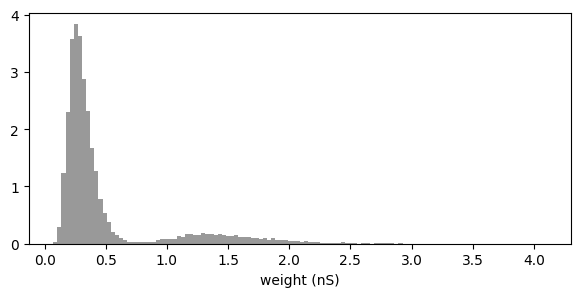

fraction above 0.9 nS: 0.145 (strong component weight 0.15)
mean: 0.478 nS (expected 0.85*0.3 + 0.15*1.5 = 0.480)


In [4]:
mixture = init.Mixture(
    distributions=[
        init.LogNormal(0.3 * u.nS, 0.1 * u.nS),  # many weak synapses
        init.LogNormal(1.5 * u.nS, 0.4 * u.nS),  # a few strong ones
    ],
    weights=[0.85, 0.15],
)
w = mixture(20_000, rng=rng).to_decimal(u.nS)

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(w, bins=120, density=True, color="0.6")
ax.set_xlabel("weight (nS)")
plt.show()
print(f"fraction above 0.9 nS: {np.mean(w > 0.9):.3f} (strong component weight 0.15)")
print(f"mean: {w.mean():.3f} nS (expected 0.85*0.3 + 0.15*1.5 = {0.85 * 0.3 + 0.15 * 1.5:.3f})")

## 4. `Conditional`: Choosing by Index

`Conditional(condition_fn, true_dist, false_dist)` evaluates `condition_fn(neuron_indices)` and draws each element from `true_dist` where the condition holds and from `false_dist` elsewhere. By default `neuron_indices` is `arange(size)` over the **flattened** array, which is natural for per-neuron vectors.

In [5]:
n_exc, n_inh = 80, 20
tau = init.Conditional(
    condition_fn=lambda i: i < n_exc,  # excitatory neurons first
    true_dist=init.Normal(20.0 * u.ms, 2.0 * u.ms),
    false_dist=init.Normal(10.0 * u.ms, 1.0 * u.ms),
)
values = tau(n_exc + n_inh, rng=rng)
print(f"excitatory tau mean {u.math.mean(values[:n_exc]):.2f}, inhibitory tau mean {u.math.mean(values[n_exc:]):.2f}")

excitatory tau mean 19.90 ms, inhibitory tau mean 9.49 ms


For a weight matrix of shape `(n_pre, n_post)` the flattened index runs over rows first, so to select by **presynaptic** neuron pass the row index of every element explicitly. Here rows from inhibitory neurons get negative weights:

In [6]:
n_pre, n_post = n_exc + n_inh, 50
row_of_element = np.repeat(np.arange(n_pre), n_post)

signed = init.Conditional(
    condition_fn=lambda i: i < n_exc,
    true_dist=init.LogNormal(0.5 * u.nS, 0.2 * u.nS),
    false_dist=-1.0 * init.LogNormal(2.0 * u.nS, 0.5 * u.nS),  # arithmetic works here too
)
W = signed((n_pre, n_post), neuron_indices=row_of_element, rng=rng)
print(f"excitatory rows all positive: {bool(u.math.all(W[:n_exc] > 0 * u.nS))}")
print(f"inhibitory rows all negative: {bool(u.math.all(W[n_exc:] < 0 * u.nS))}")

excitatory rows all positive: True
inhibitory rows all negative: True


## 5. `DistanceModulated`: Weights That Decay With Distance

`DistanceModulated(base_dist, distance_profile)` draws weights from `base_dist` and multiplies them by `distance_profile(distances)`. Provide the distances in either of two ways:

- `distances=`: an array with the same shape as the weights;
- `pre_positions=` and `post_positions=`: arrays of shape `(n_pre, n_dims)` and `(n_post, n_dims)`; the pairwise Euclidean distances are computed for you and the shape must be `(n_pre, n_post)`.

The profile multiplies the weights; it does **not** remove connections. Combine it with a connectivity mask (or a `braintools.conn` builder) when distant pairs should not be connected at all.

W shape (400, 400); W / profile(d) has mean 1.000 and std 0.100 (the base N(1, 0.1))


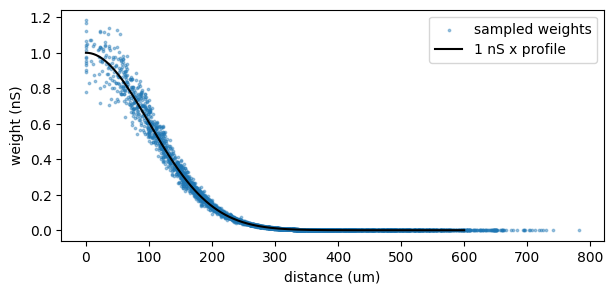

In [7]:
n = 400
positions = rng.uniform(0.0, 600.0, size=(n, 2)) * u.um
profile = init.GaussianProfile(sigma=100.0 * u.um)
weights = init.DistanceModulated(
    base_dist=init.Normal(1.0 * u.nS, 0.1 * u.nS),
    distance_profile=profile,
)
W = weights((n, n), pre_positions=positions, post_positions=positions, rng=rng)

dist = np.linalg.norm(positions.mantissa[:, None] - positions.mantissa[None], axis=-1)
ratio = W.to_decimal(u.nS) / np.asarray(profile(dist * u.um))
print(f"W shape {W.shape}; W / profile(d) has mean {ratio.mean():.3f} and std {ratio.std():.3f} (the base N(1, 0.1))")

sub = rng.choice(n * n, 4000, replace=False)
grid = np.linspace(0, 600, 300) * u.um
fig, ax = plt.subplots(figsize=(7, 3))
ax.scatter(dist.ravel()[sub], W.to_decimal(u.nS).ravel()[sub], s=3, alpha=0.4, label="sampled weights")
ax.plot(grid.mantissa, np.asarray(profile(grid)), "k", label="1 nS x profile")
ax.set_xlabel("distance (um)")
ax.set_ylabel("weight (nS)")
ax.legend()
plt.show()

## 6. Putting It Together: A Spatial E/I Weight Matrix

The pieces compose freely. The example below builds the recurrent weights of 400 excitatory and 100 inhibitory neurons on a sheet:

- connections exist with a probability that decays with distance (narrower for excitatory than for inhibitory axons);
- excitatory weights are log-normal and decay with distance;
- inhibitory weights are stronger, negative, and decay more slowly.

All parameter values are illustrative.

connection density 0.094


excitatory weights: 14763 connections, all > 0: True


inhibitory weights: 8769 connections, all < 0: True
summed incoming E / I weight per neuron (mean): 9.39 nS / -15.81 nS


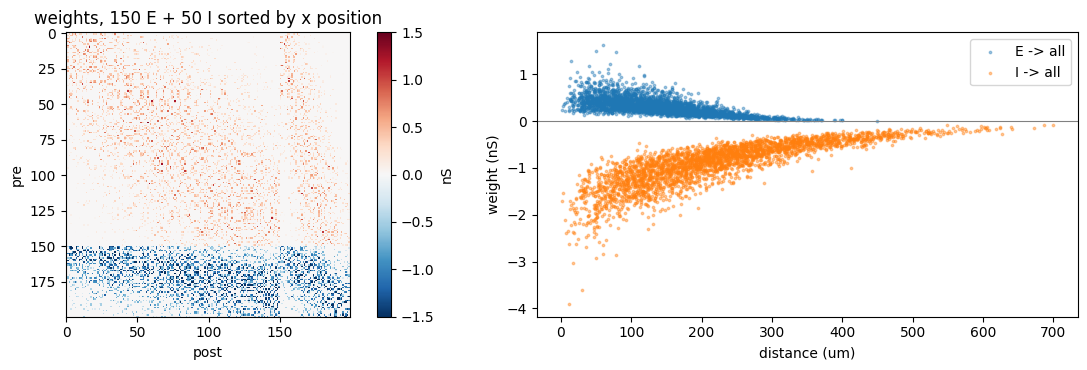

In [8]:
rng = np.random.default_rng(1)
n_e, n_i = 400, 100
n_all = n_e + n_i
pos = rng.uniform(0.0, 1000.0, size=(n_all, 2)) * u.um
is_exc = np.arange(n_all) < n_e

exc_w = init.DistanceModulated(init.LogNormal(0.5 * u.nS, 0.2 * u.nS), init.GaussianProfile(150.0 * u.um))
inh_w = -1.0 * init.DistanceModulated(init.LogNormal(2.0 * u.nS, 0.5 * u.nS), init.ExponentialProfile(250.0 * u.um))

W = u.math.zeros((n_all, n_all)) * u.nS
W[is_exc] = exc_w((n_e, n_all), pre_positions=pos[is_exc], post_positions=pos, rng=rng)
W[~is_exc] = inh_w((n_i, n_all), pre_positions=pos[~is_exc], post_positions=pos, rng=rng)

dist = np.linalg.norm(pos.mantissa[:, None] - pos.mantissa[None], axis=-1) * u.um
p_conn = np.where(is_exc[:, None],
                  init.GaussianProfile(120.0 * u.um).probability(dist),
                  init.GaussianProfile(200.0 * u.um).probability(dist))
mask = (rng.random((n_all, n_all)) < p_conn) & ~np.eye(n_all, dtype=bool)
W = u.math.where(mask, W, 0.0 * u.nS)

w = W.to_decimal(u.nS)
print(f"connection density {mask.mean():.3f}")
print(f"excitatory weights: {np.count_nonzero(w[is_exc])} connections, all > 0: {bool((w[is_exc][mask[is_exc]] > 0).all())}")
print(f"inhibitory weights: {np.count_nonzero(w[~is_exc])} connections, all < 0: {bool((w[~is_exc][mask[~is_exc]] < 0).all())}")
print(f"summed incoming E / I weight per neuron (mean): {w[is_exc].sum(0).mean():.2f} nS / {w[~is_exc].sum(0).mean():.2f} nS")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
order = np.argsort(pos.mantissa[:, 0])  # sort by x so local structure is visible
sel = np.concatenate([order[is_exc[order]][:150], order[~is_exc[order]][:50]])
im = axes[0].imshow(w[np.ix_(sel, sel)], cmap="RdBu_r", vmin=-1.5, vmax=1.5, interpolation="nearest")
axes[0].set_title("weights, 150 E + 50 I sorted by x position")
axes[0].set_xlabel("post")
axes[0].set_ylabel("pre")
fig.colorbar(im, ax=axes[0], label="nS")
d = dist.mantissa
axes[1].scatter(d[is_exc][mask[is_exc]][:3000], w[is_exc][mask[is_exc]][:3000], s=3, alpha=0.4, label="E -> all")
axes[1].scatter(d[~is_exc][mask[~is_exc]][:3000], w[~is_exc][mask[~is_exc]][:3000], s=3, alpha=0.4, label="I -> all")
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set_xlabel("distance (um)")
axes[1].set_ylabel("weight (nS)")
axes[1].legend()
fig.tight_layout()
plt.show()

## 7. `param`: Accepting Any Initializer

Models in the BrainX ecosystem usually let users pass a number, an array, or an initializer for each parameter. `init.param(value, shape)` turns any of them into an array of that shape:

- an initializer (or any callable) is called with the shape;
- an array is checked to be broadcast-compatible with the shape and returned;
- a scalar is returned as is (unless `allow_scalar=False`), and `None` as `None` (unless `allow_none=False`);
- `batch_size=` prepends a batch axis.

In [9]:
shape = (4,)
print(init.param(init.Normal(-65.0 * u.mV, 1.0 * u.mV), shape, rng=np.random.default_rng(0)))
print(init.param(np.full(shape, -70.0) * u.mV, shape))
print(init.param(-65.0 * u.mV, shape))
print(init.param(init.Constant(-65.0 * u.mV), shape, batch_size=2).shape)

try:
    init.param(np.zeros(3), shape)
except ValueError as exc:
    print("shape mismatch ->", exc)

[-64.87426978 -65.13210486 -64.35957735 -64.89509988] mV
[-70. -70. -70. -70.] mV
-65. mV
(2, 4)
shape mismatch -> The shape of the parameter (3,) does not match with the given size (4,)


## Summary

- Initializers compose with arithmetic, `.clip`, `.apply`, `|`, and `Compose`; every leaf initializer draws independently.
- `Mixture` mixes components per element; `Conditional` chooses by index. For matrices, pass `neuron_indices` to select by row.
- `DistanceModulated` multiplies weights by a distance profile; give `distances` or `pre_positions` / `post_positions`. It scales weights but does not prune connections.
- `param` accepts initializers, arrays, and scalars alike, which is how models expose flexible parameters.